### EDA

#### Import thư viện và đọc dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (140700, 20)
Test shape: (93800, 19)


#### Thông tin tổng quan

In [2]:
train.info()
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 140700 entries, 0 to 140699
Data columns (total 20 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   id                                     140700 non-null  int64  
 1   Name                                   140700 non-null  str    
 2   Gender                                 140700 non-null  str    
 3   Age                                    140700 non-null  float64
 4   City                                   140700 non-null  str    
 5   Working Professional or Student        140700 non-null  str    
 6   Profession                             104070 non-null  str    
 7   Academic Pressure                      27897 non-null   float64
 8   Work Pressure                          112782 non-null  float64
 9   CGPA                                   27898 non-null   float64
 10  Study Satisfaction                     27897 non-null   float64
 11

In [3]:
train.describe()
test.describe()

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress
count,93800.000000,93800.000000,18767.000000,75022.000000,18766.000000,18767.000000,75026.00000,93800.000000,93800.000000
mean,187599.500000,40.321685,3.158576,3.011797,7.674016,2.939522,2.96092,6.247335,2.978763
std,27077.871962,12.393480,1.386666,1.403563,1.465056,1.374242,1.41071,3.858191,1.414604
min,140700.000000,18.000000,1.000000,1.000000,5.030000,1.000000,1.00000,0.000000,1.000000
25%,164149.750000,29.000000,2.000000,2.000000,6.330000,2.000000,2.00000,3.000000,2.000000
50%,187599.500000,42.000000,3.000000,3.000000,7.800000,3.000000,3.00000,6.000000,3.000000
75%,211049.250000,51.000000,4.000000,4.000000,8.940000,4.000000,4.00000,10.000000,4.000000
max,234499.000000,60.000000,5.000000,5.000000,10.000000,5.000000,5.00000,12.000000,5.000000


#### missing values

In [4]:
def missing_summary(df, name):
    missing = df.isnull().sum()
    missing_pct = 100 * missing / len(df)
    missing_df = pd.DataFrame({'Số lượng missing': missing, 'Tỷ lệ %': missing_pct})
    missing_df = missing_df[missing_df['Số lượng missing'] > 0].sort_values('Tỷ lệ %', ascending=False)
    print(f"=== {name} - Missing values ===")
    print(missing_df)
    return missing_df

In [5]:
missing_train = missing_summary(train, "TRAIN")
missing_test = missing_summary(test, "TEST")

=== TRAIN - Missing values ===
                    Số lượng missing    Tỷ lệ %
Academic Pressure             112803  80.172708
Study Satisfaction            112803  80.172708
CGPA                          112802  80.171997
Profession                     36630  26.034115
Work Pressure                  27918  19.842217
Job Satisfaction               27910  19.836532
Dietary Habits                     4   0.002843
Financial Stress                   4   0.002843
Degree                             2   0.001421
=== TEST - Missing values ===
                    Số lượng missing    Tỷ lệ %
CGPA                           75034  79.993603
Academic Pressure              75033  79.992537
Study Satisfaction             75033  79.992537
Profession                     24632  26.260128
Work Pressure                  18778  20.019190
Job Satisfaction               18774  20.014925
Dietary Habits                     5   0.005330
Degree                             2   0.002132


**Nhận xét:**

Các cột Academic Pressure, Study Satisfaction, CGPA missing ~80% – đây là dữ liệu chỉ có ở nhóm học sinh/sinh viên.

Profession missing ~26% – chỉ có ở nhóm đi làm.

Các cột còn lại missing rất ít (<0.01%).

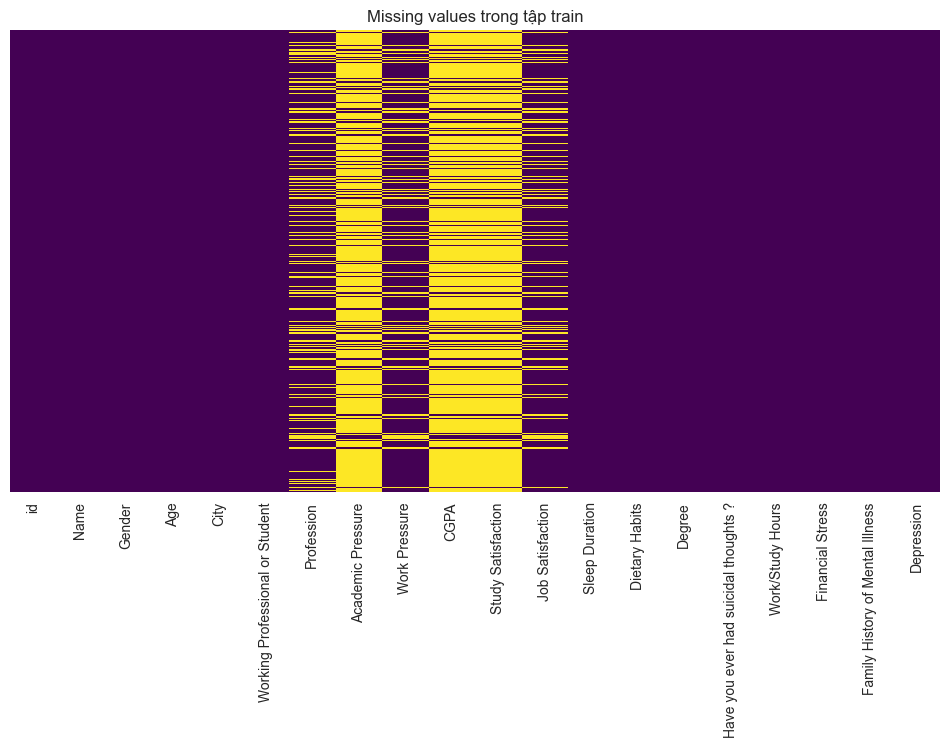

In [6]:
plt.figure(figsize=(12,6))
sns.heatmap(train.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing values trong tập train')
plt.show()

**Nhận xét:**

Hình ảnh trực quan cho thấy vùng missing tập trung rõ rệt ở các cột Profession, Academic Pressure, Work Pressure, CGPA, Study Satisfaction, Job Satisfaction.

Missing có cấu trúc theo nhóm đối tượng, không ngẫu nhiên hoàn toàn.

#### Phân phối biến mục tiêu Depression

In [7]:
print("Phân phối Depression trong train:")
print(train['Depression'].value_counts())
print("\nTỷ lệ phần trăm:")
print(train['Depression'].value_counts(normalize=True) * 100)

Phân phối Depression trong train:
Depression
0    115133
1     25567
Name: count, dtype: int64

Tỷ lệ phần trăm:
Depression
0    81.828714
1    18.171286
Name: proportion, dtype: float64


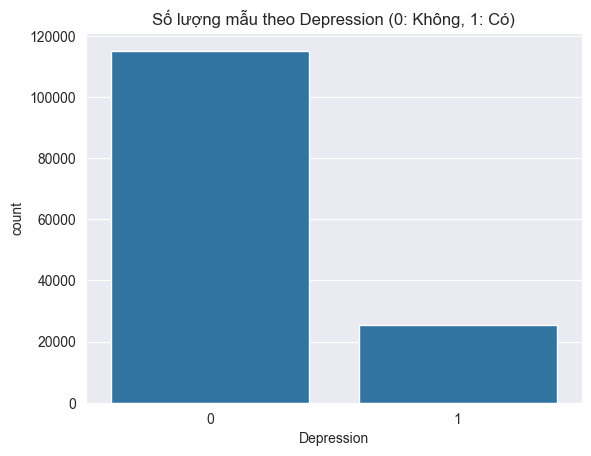

In [8]:
sns.countplot(x='Depression', data=train)
plt.title('Số lượng mẫu theo Depression (0: Không, 1: Có)')
plt.show()

**Nhận xét:**

Lớp 0 (không trầm cảm): 115.133 (~81,8%)

Lớp 1 (có trầm cảm): 25.567 (~18,2%)

Biểu đồ cột xác nhận sự mất cân bằng, cần lưu ý khi xây dựng mô hình.

#### Phát hiện outlier

In [9]:
num_cols = ['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress', 'Academic Pressure', 'Work Pressure']

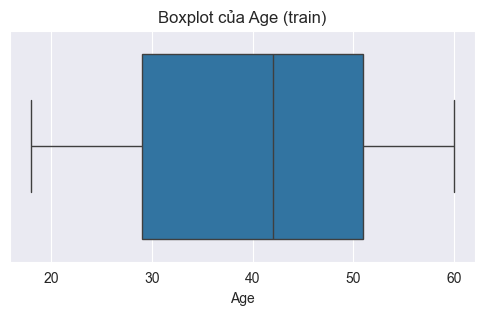

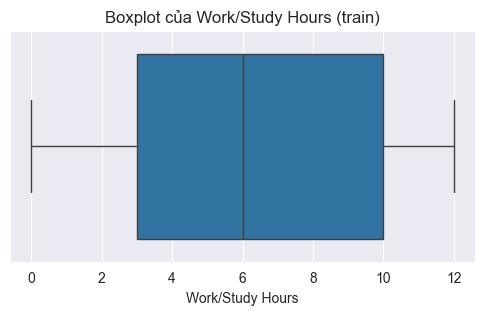

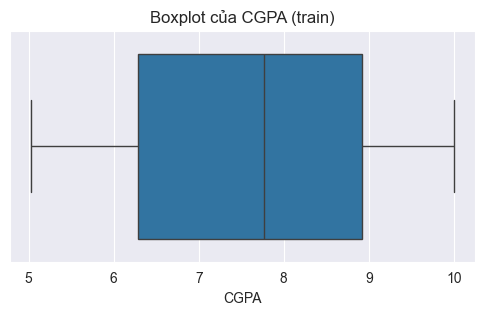

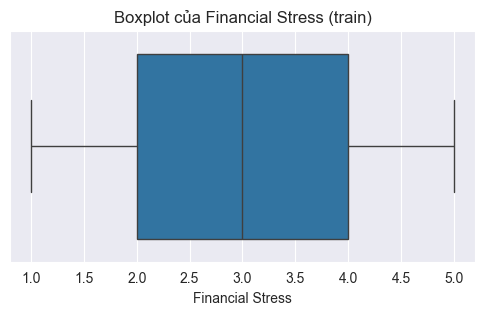

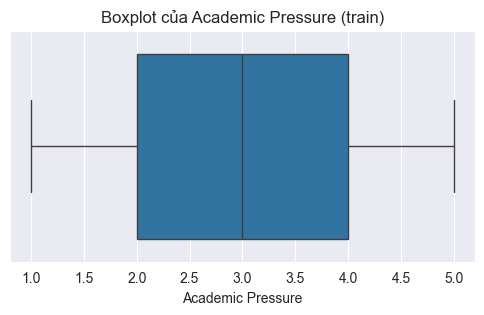

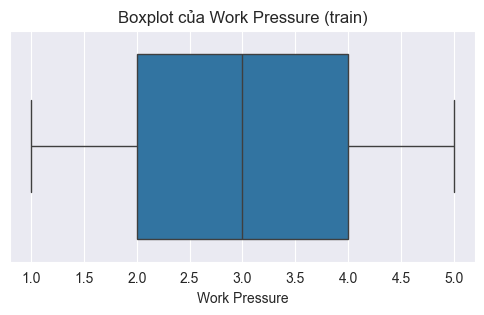

In [10]:
for col in num_cols:
    if col in train.columns:
        plt.figure(figsize=(6,3))
        sns.boxplot(x=train[col])
        plt.title(f'Boxplot của {col} (train)')
        plt.show()

**Nhận xét:**

Các biến Age, Work/Study Hours, CGPA, Financial Stress, Academic Pressure, Work Pressure đều có outlier, đặc biệt là Work/Study Hours có nhiều outlier ở mức cao.

#### Kiểm tra giá trị unique của các biến phân loại

In [11]:
cat_cols = train.select_dtypes(include=['object','string']).columns
for col in cat_cols:
    print(f"\n=== {col} (train) ===")
    print("Unique values:", train[col].dropna().unique()[:20])  # hiển thị tối đa 20 giá trị
    print("Số lượng unique:", train[col].nunique())


=== Name (train) ===
Unique values: <StringArray>
[ 'Aaradhya',     'Vivan',    'Yuvraj',      'Rhea',      'Vani',    'Ritvik',
   'Rajveer', 'Aishwarya',    'Simran',   'Utkarsh',    'Aahana',     'Tejas',
    'Aadhya',     'Kiran',     'Aditi',    'Suhani',      'Jiya',   'Bhavesh',
    'Armaan',   'Ishaani']
Length: 20, dtype: str
Số lượng unique: 422

=== Gender (train) ===
Unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Số lượng unique: 2

=== City (train) ===
Unique values: <StringArray>
[     'Ludhiana',      'Varanasi', 'Visakhapatnam',        'Mumbai',
        'Kanpur',     'Ahmedabad',         'Thane',        'Nashik',
     'Bangalore',         'Patna',        'Rajkot',        'Jaipur',
          'Pune',       'Lucknow',        'Meerut',          'Agra',
         'Surat',     'Faridabad',     'Hyderabad',      'Srinagar']
Length: 20, dtype: str
Số lượng unique: 98

=== Working Professional or Student (train) ===
Unique values: <StringArray>
['Working P

**Nhận xét:**

Gender: 2 giá trị (Female, Male).

City: 98 thành phố khác nhau.

Profession: 64 nghề nghiệp.

Sleep Duration: có nhiều giá trị bất thường

Dietary Habits và Degree cũng có nhiều giá trị lỗi hoặc không nhất quán

#### So sánh train/test về cấu trúc và missing

In [12]:
print("So sánh missing pattern:")
missing_compare = pd.DataFrame({
    'Train missing %': train.isnull().sum() / len(train) * 100,
    'Test missing %': test.isnull().sum() / len(test) * 100
})
missing_compare = missing_compare[(missing_compare['Train missing %'] > 0) | (missing_compare['Test missing %'] > 0)]
print(missing_compare)

So sánh missing pattern:
                    Train missing %  Test missing %
Academic Pressure         80.172708       79.992537
CGPA                      80.171997       79.993603
Degree                     0.001421        0.002132
Dietary Habits             0.002843        0.005330
Financial Stress           0.002843        0.000000
Job Satisfaction          19.836532       20.014925
Profession                26.034115       26.260128
Study Satisfaction        80.172708       79.992537
Work Pressure             19.842217       20.019190


In [13]:
print("\nSo sánh kiểu dữ liệu:")
print(pd.DataFrame({'Train dtype': train.dtypes, 'Test dtype': test.dtypes}))


So sánh kiểu dữ liệu:
                                      Train dtype Test dtype
Academic Pressure                         float64    float64
Age                                       float64    float64
CGPA                                      float64    float64
City                                          str        str
Degree                                        str        str
Depression                                  int64        NaN
Dietary Habits                                str        str
Family History of Mental Illness              str        str
Financial Stress                          float64    float64
Gender                                        str        str
Have you ever had suicidal thoughts ?         str        str
Job Satisfaction                          float64    float64
Name                                          str        str
Profession                                    str        str
Sleep Duration                                str        str
S

**Nhận xét:**

Tỷ lệ missing giữa train và test tương đồng, phù hợp để xây dựng mô hình.

Kiểu dữ liệu các cột giống nhau, chỉ khác cột Depression chỉ có trong train.

#### Histogram các biến số

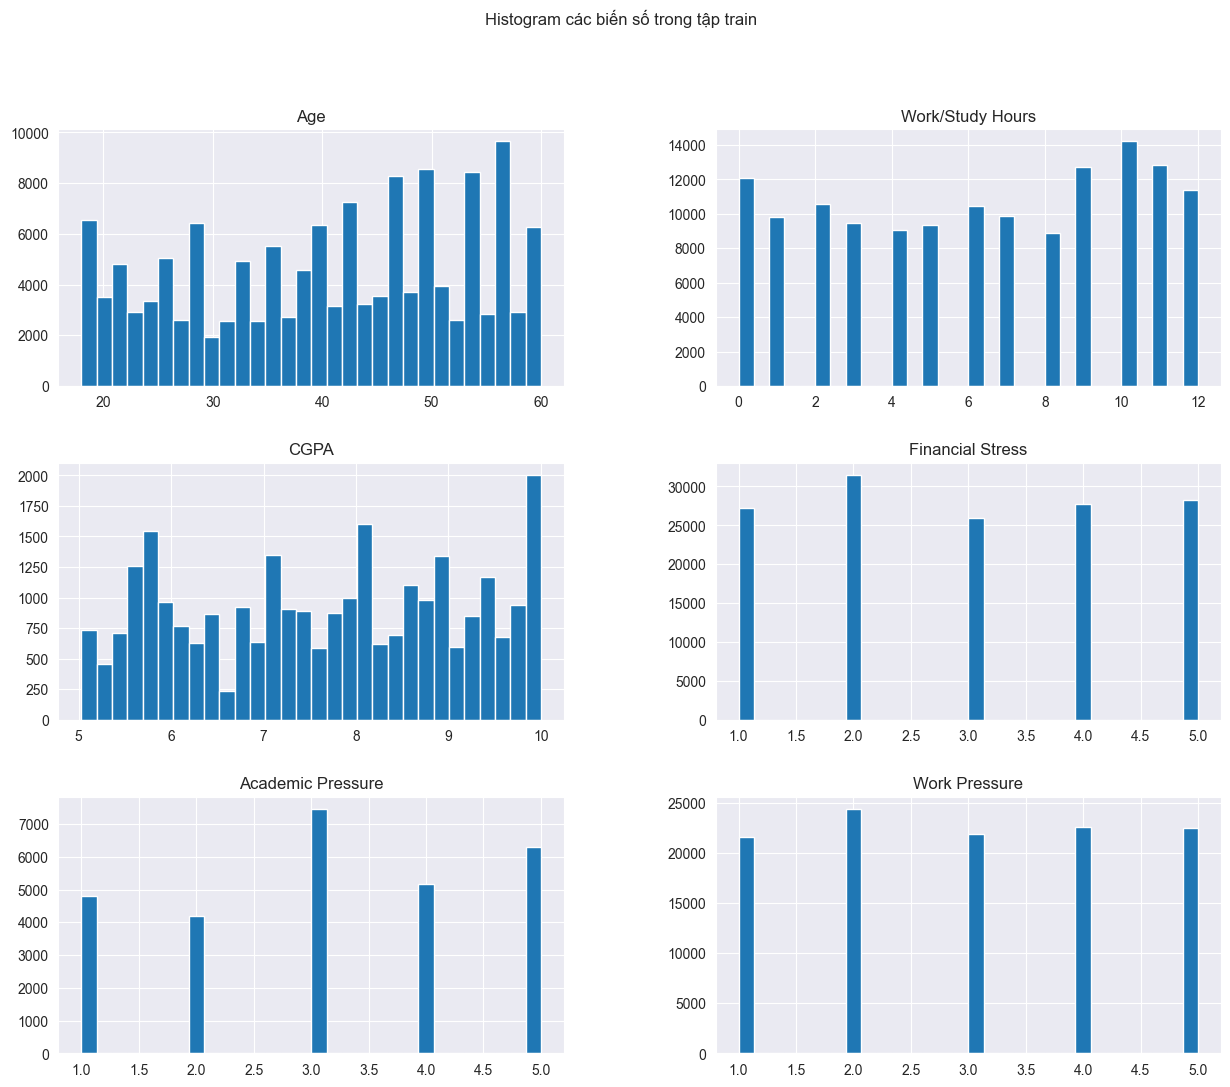

In [14]:
train[num_cols].hist(bins=30, figsize=(15,12))
plt.suptitle('Histogram các biến số trong tập train')
plt.show()

**Nhận xét:**

Age phân bố gần đều, hơi lệch phải.

Work/Study Hours có hai đỉnh (~3 và ~8–10 giờ).

CGPA phân bố tập trung quanh 7–9.

Financial Stress, Academic Pressure, Work Pressure có xu hướng tập trung ở mức trung bình

#### Biểu đồ cột cho biến phân loại theo Depression

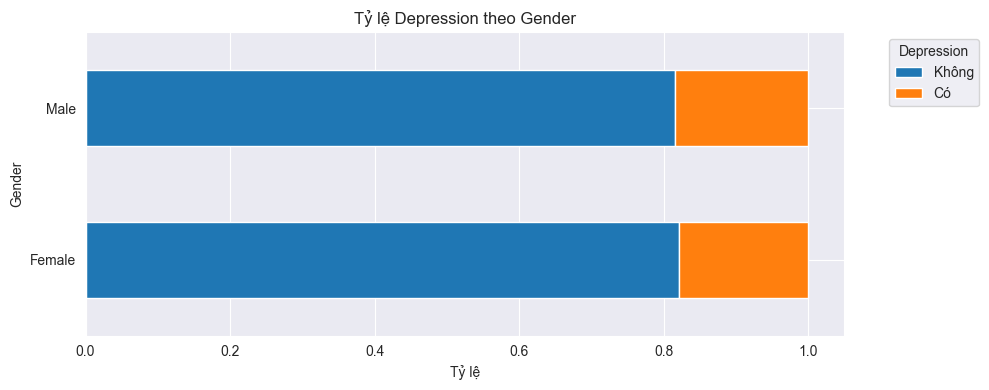

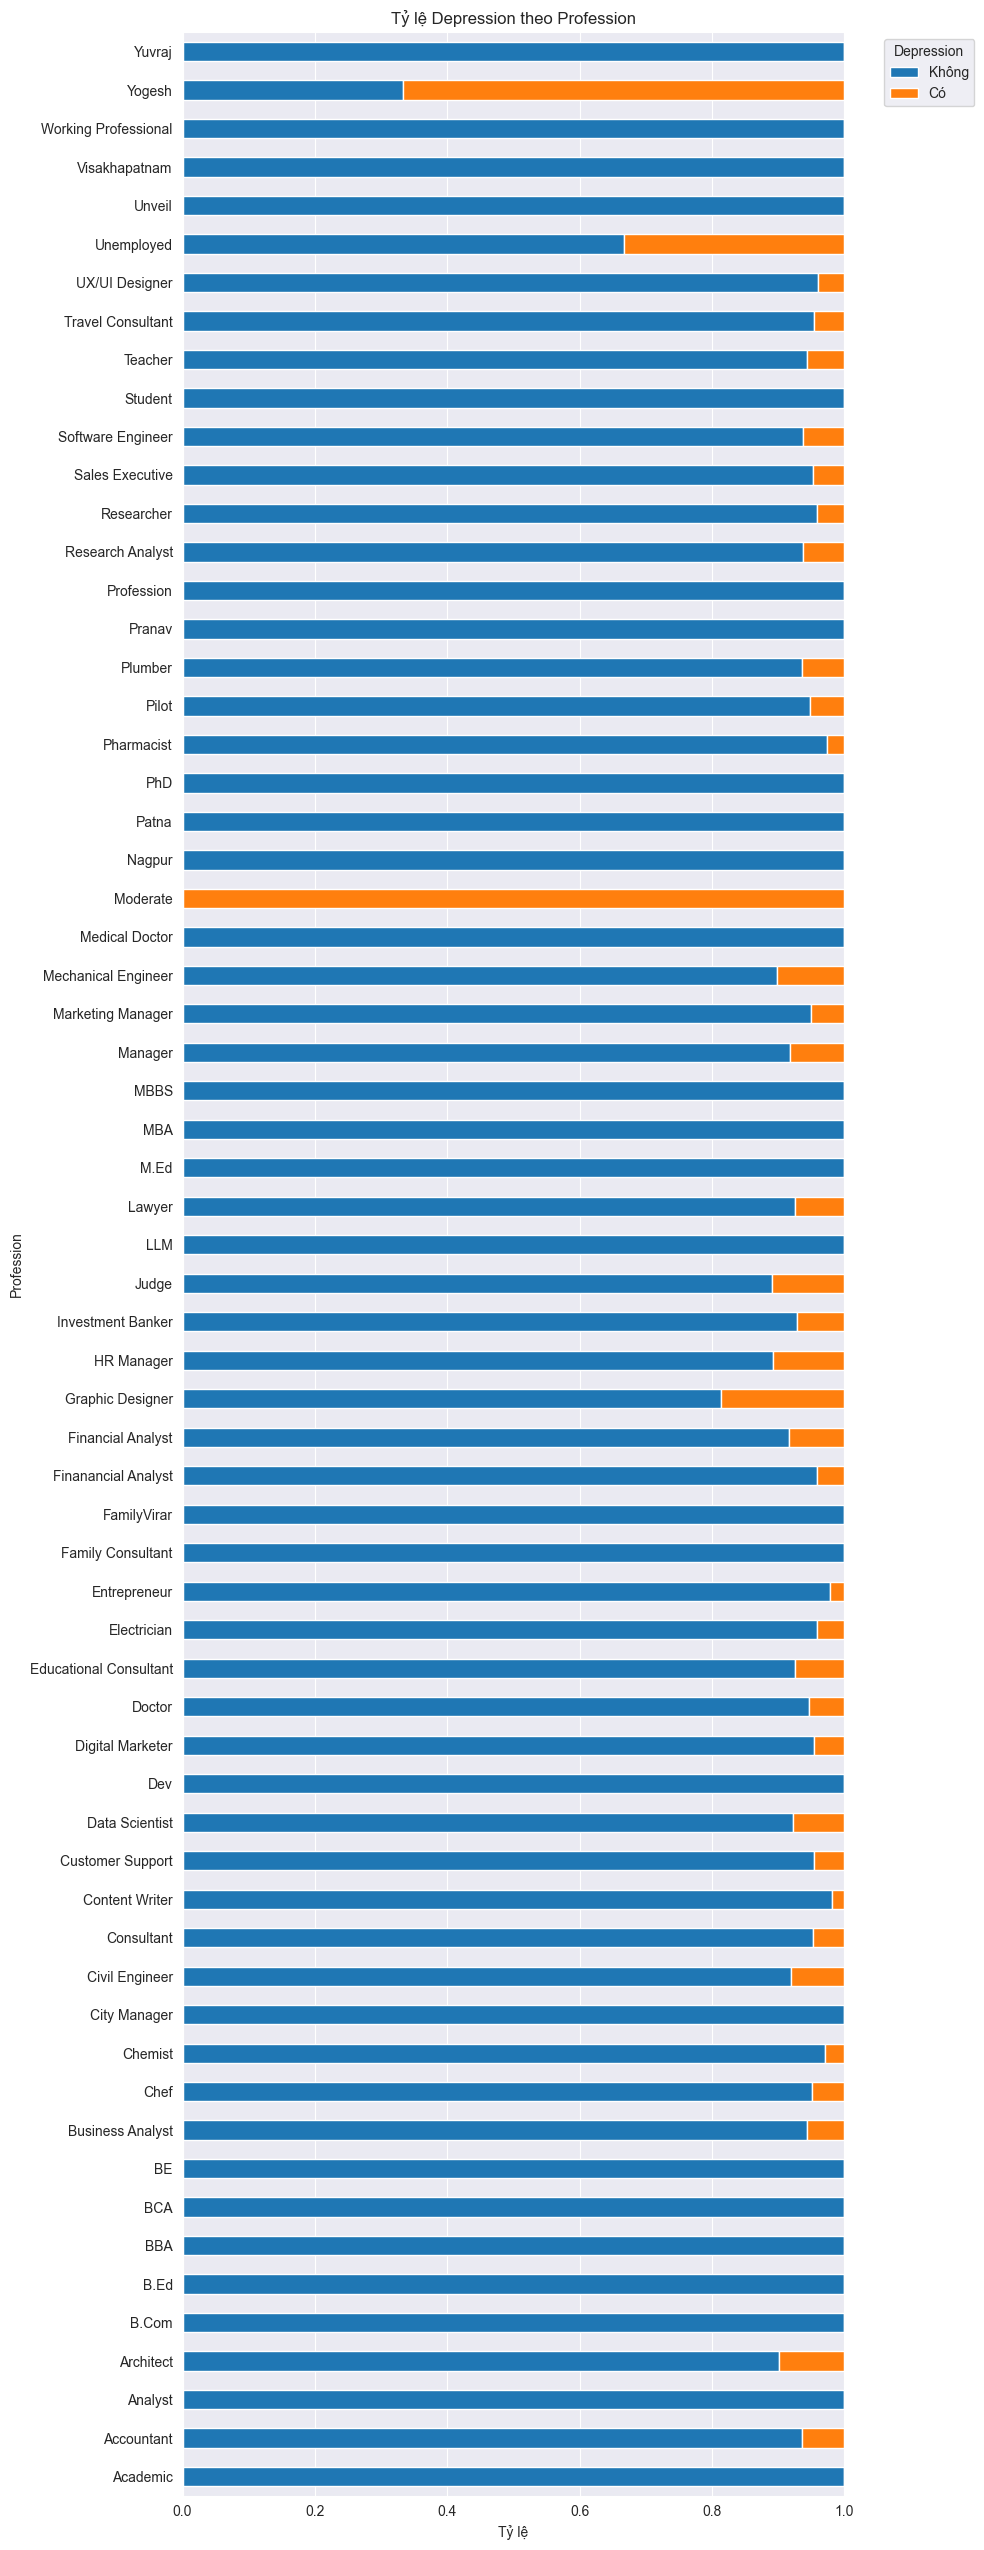

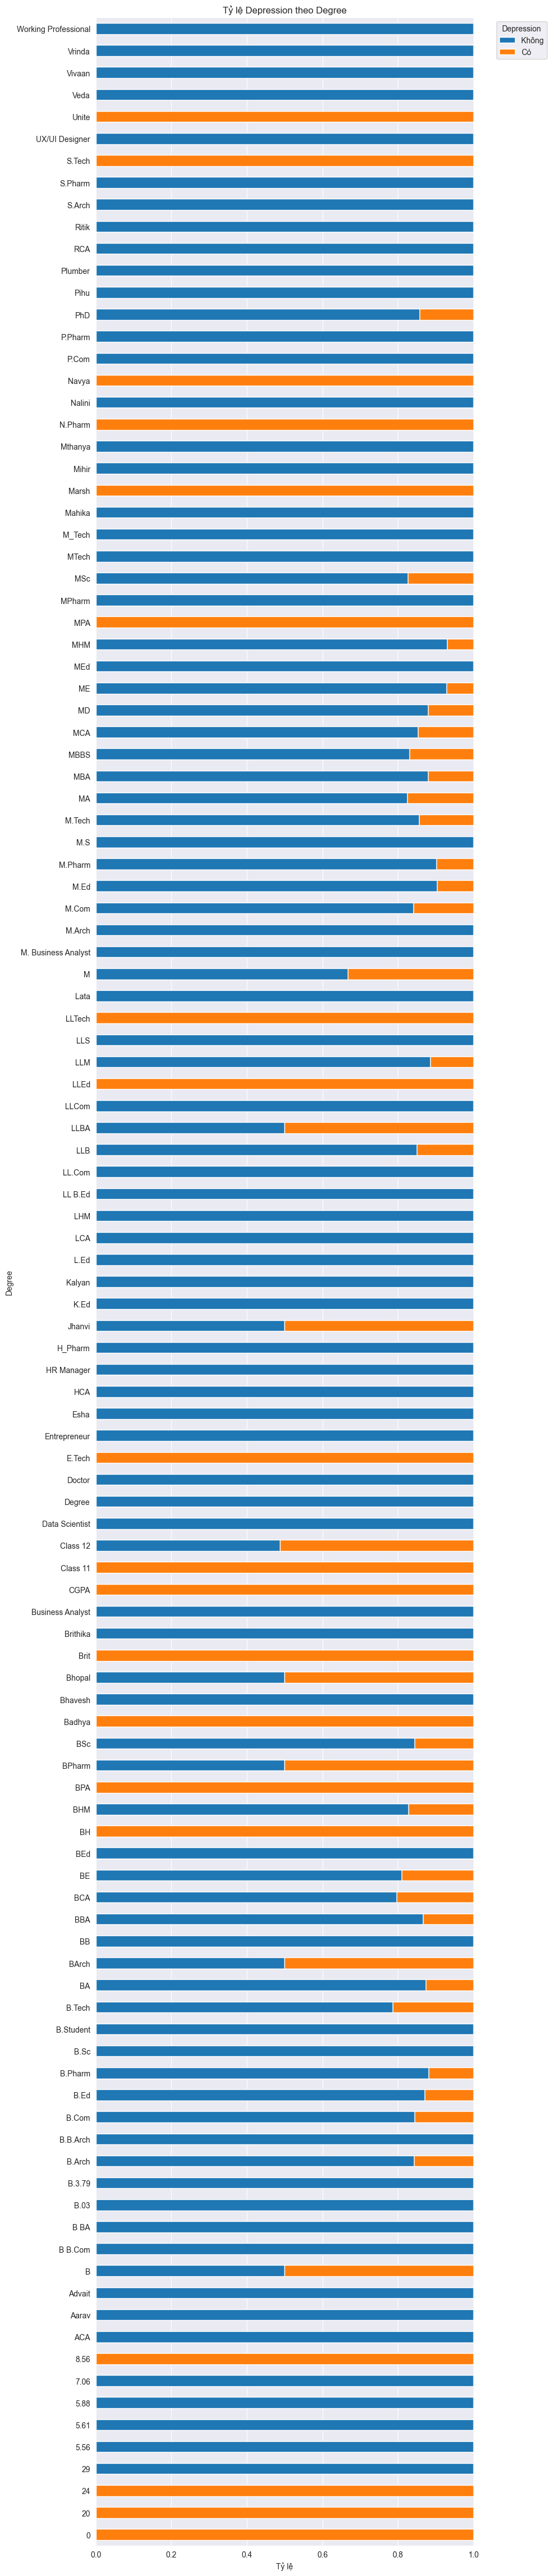

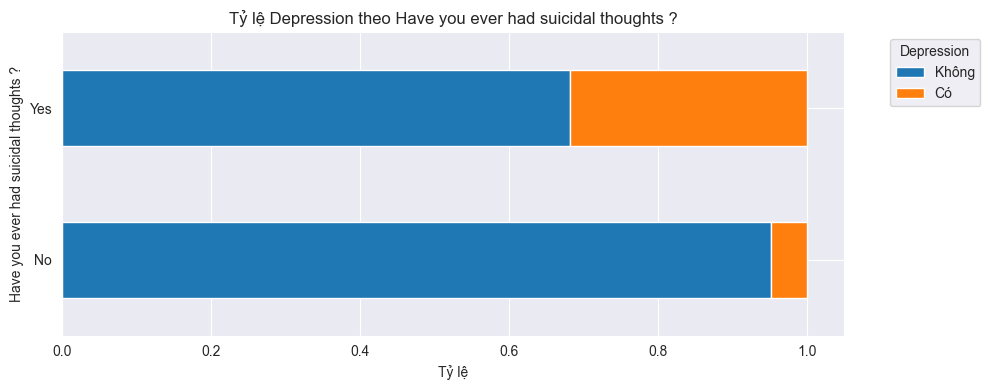

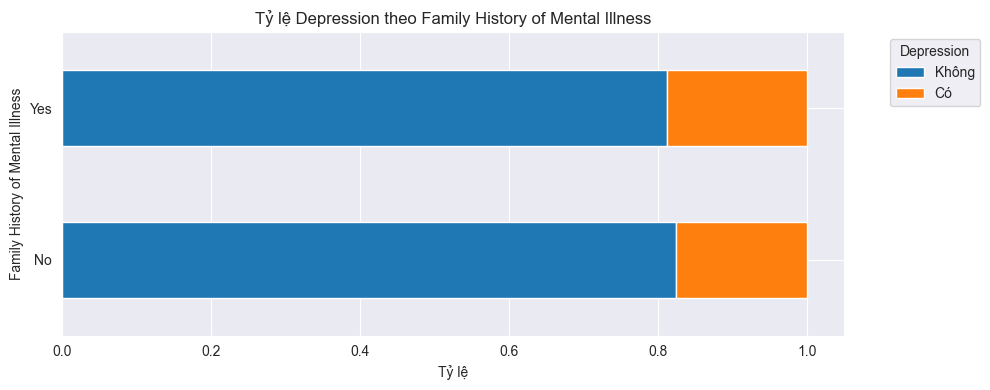

In [15]:
cat_target = ['Gender', 'Profession', 'Degree', 'Marital Status',
               'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']
for col in cat_target:
    if col in train.columns:
        plt.figure(figsize=(10, max(4, train[col].nunique() * 0.4)))
        cross = pd.crosstab(train[col], train['Depression'], normalize='index')
        cross.plot(kind='barh', stacked=True, ax=plt.gca())
        plt.title(f'Tỷ lệ Depression theo {col}')
        plt.xlabel('Tỷ lệ')
        plt.ylabel(col)
        plt.legend(title='Depression', labels=['Không', 'Có'], bbox_to_anchor=(1.05, 1))
        plt.tight_layout()
        plt.show()

**Nhận xét:**

Gender: tỷ lệ trầm cảm ở nam cao hơn nữ.

Have you ever had suicidal thoughts ?: nhóm trả lời "Yes" có tỷ lệ trầm cảm rất cao.

Family History of Mental Illness: nhóm có tiền sử gia đình cũng có tỷ lệ trầm cảm cao hơn.

#### Correlation heatmap

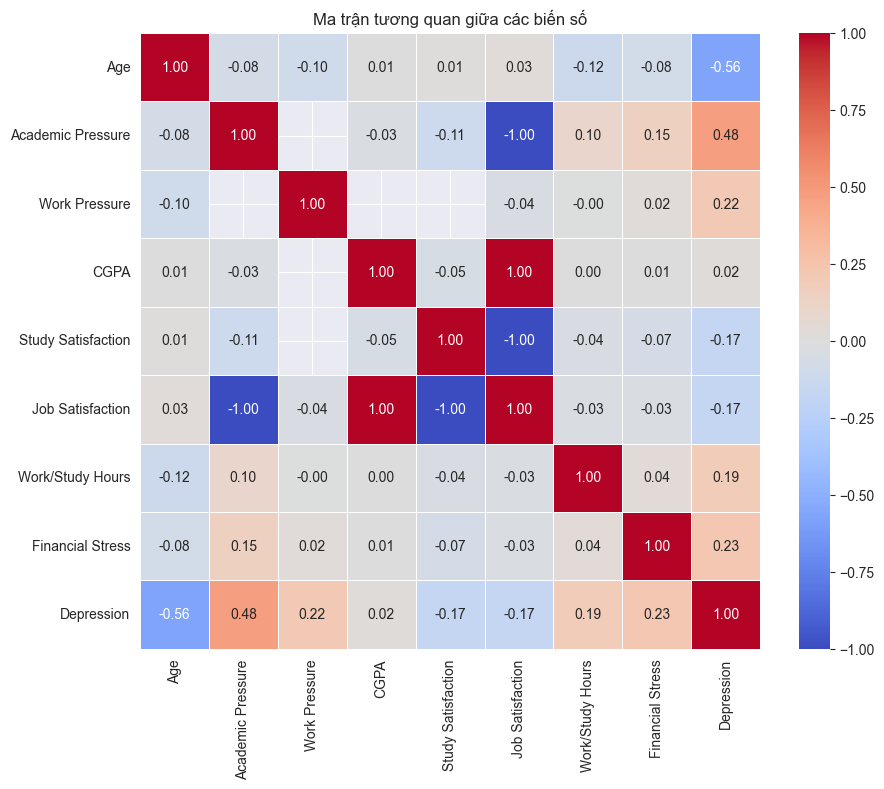

In [16]:
num_corr = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction',
            'Job Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Depression']
# Chỉ lấy các cột tồn tại
num_corr = [c for c in num_corr if c in train.columns]
corr = train[num_corr].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Ma trận tương quan giữa các biến số')
plt.show()

**Nhận xét:** Mối tương quan giữa Depression và các biến số không quá cao, cao nhất là với Academic Pressure và Financial Stress.

#### Bivariate analysis - Boxplot Depression vs các biến số

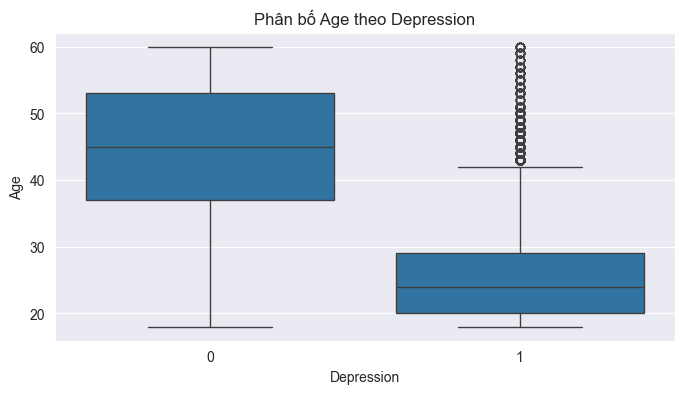

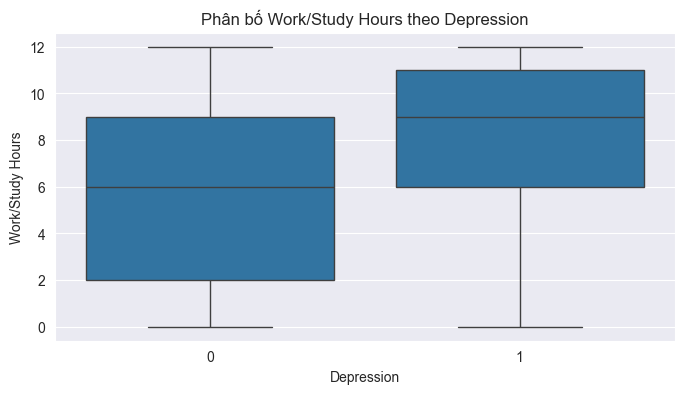

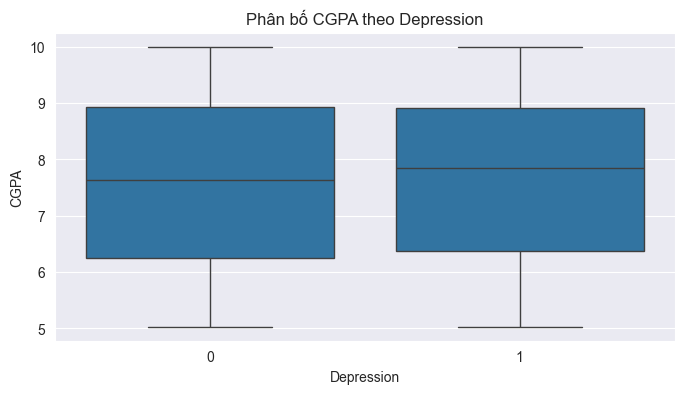

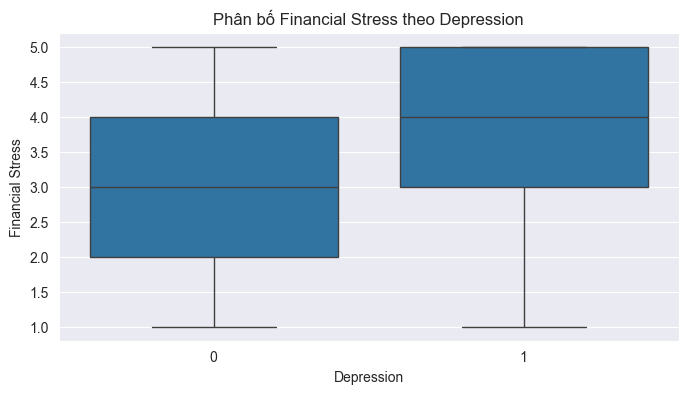

In [17]:
vars_to_plot = ['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress']
for col in vars_to_plot:
    if col in train.columns:
        plt.figure(figsize=(8,4))
        sns.boxplot(x='Depression', y=col, data=train)
        plt.title(f'Phân bố {col} theo Depression')
        plt.show()

**Nhận xét:**

Age: nhóm bị trầm cảm có độ tuổi trung bình nhỏ (thường xuất hiện ở người trẻ).

Work/Study Hours: nhóm trầm cảm có xu hướng làm việc/học tập nhiều giờ hơn.

CGPA: Hai nhóm có phân bố CGPA gần như giống nhau.

Financial Stress: nhóm trầm cảm có mức căng thẳng tài chính cao hơn rõ rệt.

#### Phân tích nhóm tuổi

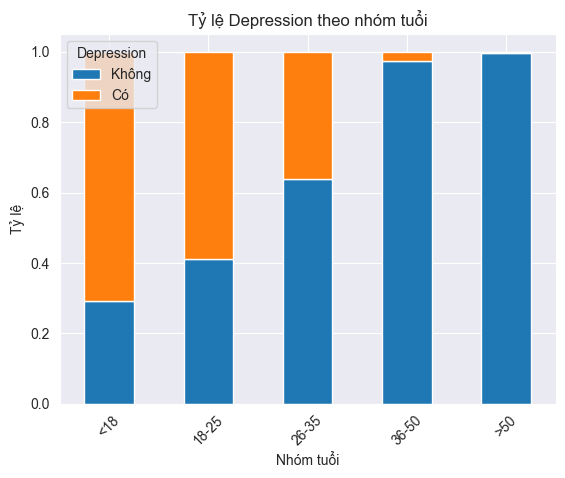

In [18]:
bins = [0, 18, 25, 35, 50, 100]
labels = ['<18', '18-25', '26-35', '36-50', '>50']
train['AgeGroup'] = pd.cut(train['Age'], bins=bins, labels=labels)
age_dep = pd.crosstab(train['AgeGroup'], train['Depression'], normalize='index')
age_dep.plot(kind='bar', stacked=True)
plt.title('Tỷ lệ Depression theo nhóm tuổi')
plt.xlabel('Nhóm tuổi')
plt.ylabel('Tỷ lệ')
plt.legend(title='Depression', labels=['Không', 'Có'])
plt.xticks(rotation=45)
plt.show()

**Nhận xét:** Nhóm tuổi <18 và 18-25 có tỷ lệ trầm cảm cao nhất.

#### Pairplot

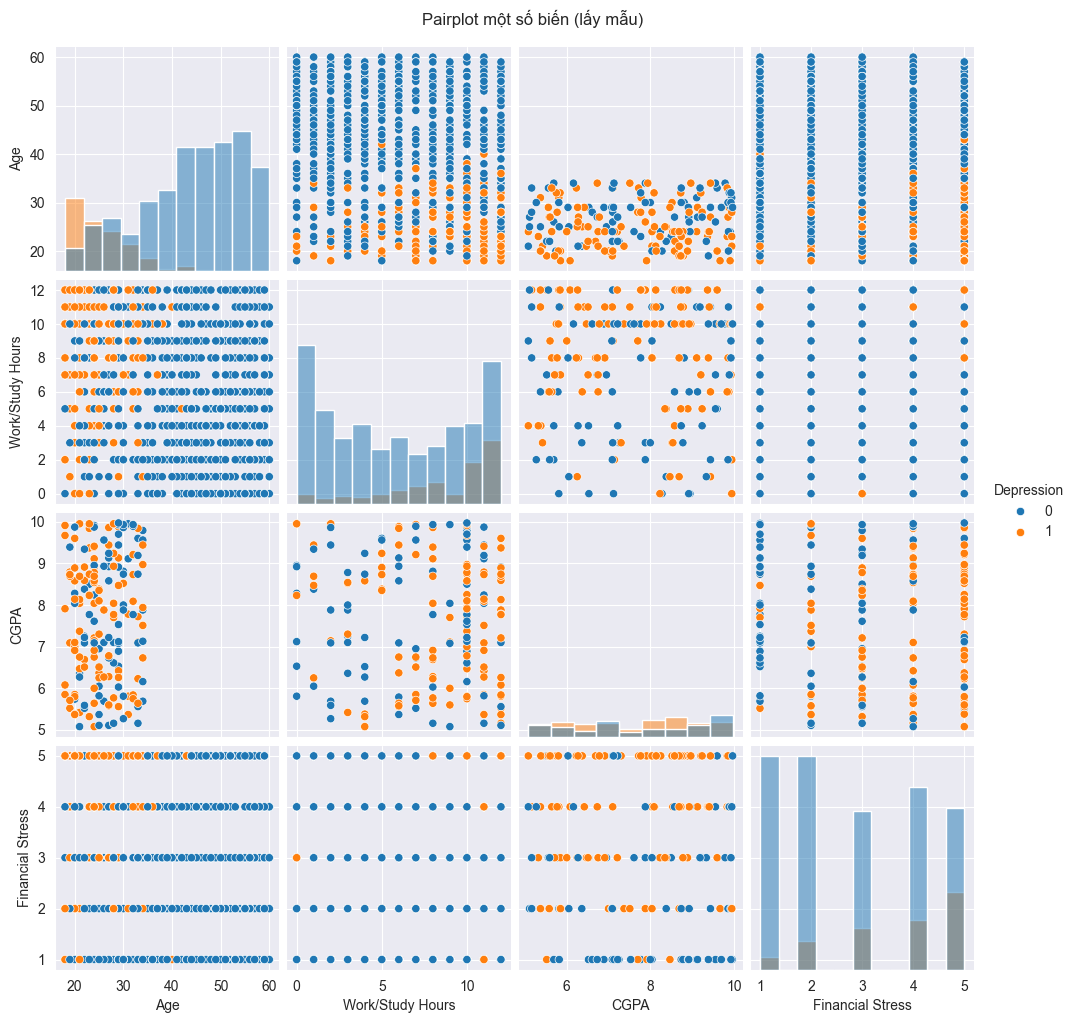

In [19]:
sample = train.sample(min(1000, len(train)))
sns.pairplot(sample[['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress', 'Depression']],
             hue='Depression', diag_kind='hist', height=2.5)
plt.suptitle('Pairplot một số biến (lấy mẫu)', y=1.02)
plt.show()

**Nhận xét:**

Age: Trải từ ~18 đến ~60, tập trung nhiều ở < 25, nhiều mức tuổi, không phụ thuộc rõ vào tuổi

Work/Study Hours: Phân tán từ 0–12 giờ, khá đều, nhiều mức giờ học/làm, không có pattern mạnh

CGPA: Chủ yếu từ 5–9, không cho thấy sự khác biệt rõ ràng giữa 2 nhóm

Financial Stress: Rời rạc từ 1–5, nhóm trầm cảm có xu hướng xuất hiện nhiều hơn ở mức Financial Stress cao (4–5)

=> Financial Stress có vẻ là yếu tố liên quan nhất đến trầm cảm

#### So sánh phân phối giữa train và test

C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[col].dropna(), label='Train', shade=True)
C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(test[col].dropna(), label='Test', shade=True)


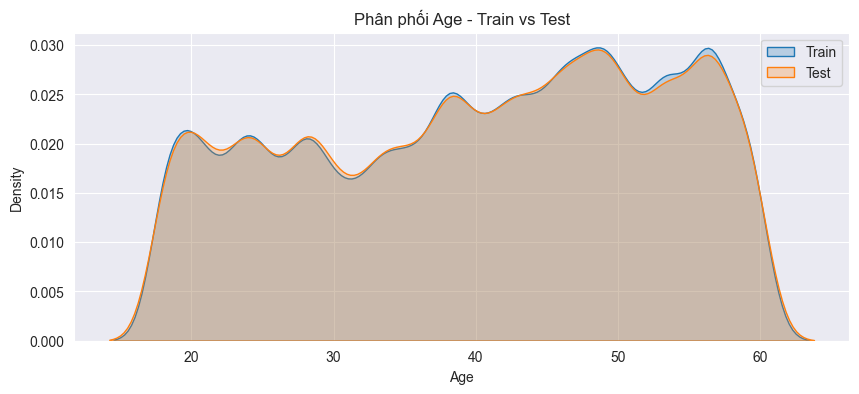

C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[col].dropna(), label='Train', shade=True)
C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(test[col].dropna(), label='Test', shade=True)


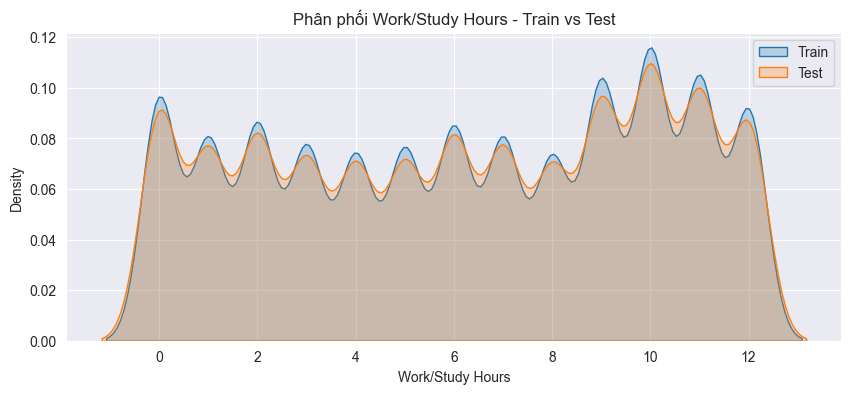

C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[col].dropna(), label='Train', shade=True)
C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(test[col].dropna(), label='Test', shade=True)


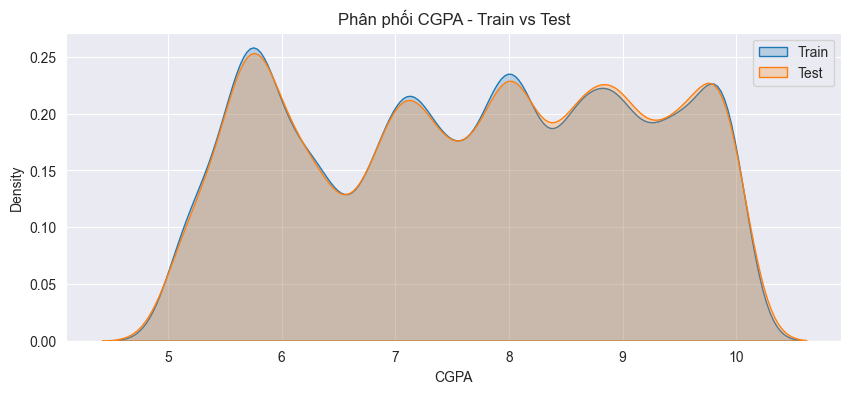

C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[col].dropna(), label='Train', shade=True)
C:\Users\nguye\AppData\Local\Temp\ipykernel_15504\84455712.py:6: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(test[col].dropna(), label='Test', shade=True)


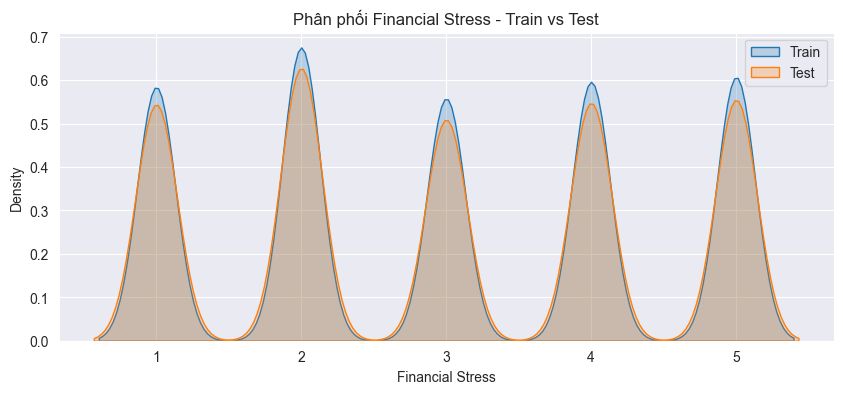

In [20]:
compare_cols = ['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress']
for col in compare_cols:
    if col in train.columns and col in test.columns:
        plt.figure(figsize=(10,4))
        sns.kdeplot(train[col].dropna(), label='Train', shade=True)
        sns.kdeplot(test[col].dropna(), label='Test', shade=True)
        plt.title(f'Phân phối {col} - Train vs Test')
        plt.legend()
        plt.show()

**Nhận xét:** Phân phối của Age, Work/Study Hours, CGPA, Financial Stress giữa train và test rất tương đồng, dữ liệu được chia ngẫu nhiên hoặc có cùng phân phối nền, tốt cho việc xây dựng mô hình.

#### Phát hiện giá trị phân loại chỉ có trong test

In [21]:
cat_cols = train.select_dtypes(include=['object','string']).columns
for col in cat_cols:
    if col in test.columns:
        train_vals = set(train[col].dropna().unique())
        test_vals = set(test[col].dropna().unique())
        only_test = test_vals - train_vals
        if only_test:
            print(f"'{col}' có giá trị chỉ xuất hiện trong test: {only_test}")

'Name' có giá trị chỉ xuất hiện trong test: {'Ivi', 'Shransh', 'Aupal', 'Adik', 'Aalalav', 'Tanvik', 'Pr.Ed', 'Ishil', 'Aaroor', 'Rudhi', 'Pranch', 'Yashish', 'Kolkata Consultant', 'Parit', 'Ritva', 'Raghavadhya', 'Zvi', 'Riket', 'Vivi', 'Nikhaan', 'Ajai', 'Aneshv', 'Aarsha', 'Siddi', 'Vivar', 'Aandini', 'Vihaly', 'Kartishti', 'Adib', 'Aarod', 'Vaina', 'Vidara', 'Vaaya', 'Vai', 'Rya', 'Aeshita', 'Avaan', 'Vihirar', 'Chibha', 'Aradhya', 'Rakash', 'Naham', 'Anwar', 'Abrit', 'Vivian', 'Harshot', 'Shrin', 'K.Ed', 'Managan', 'Aamir', 'Trav', 'Ruprav', 'Vane', 'Ananchal', 'Abra', 'Priya', 'Prreveal', 'Ashita', 'Tanveer', 'Kibha', 'Pruti', 'Anarav', 'Raghavr', 'Surat', 'Sohan', 'Aarjun', 'Ejma', 'Prani', 'Kikeya', 'Simplicio', 'Anishwarya', 'Rakav', 'Manani', 'Anita', 'Yashi', 'Ruprey', 'Darshil', 'Anmay', 'Kanket', 'Jha', 'Dalvik', 'Krishna/ Krishna', 'Aandla', 'AHM', 'Aar', 'Harshit', 'Shivani', 'Bhauri', 'R. Bhavna', 'Kishti', 'Ishin', 'Rishma', 'Nikhi', 'Ritita', 'Tanika', 'Rajika', 'Ewir